#**TC01: Load the dataset**

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer

data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = (data.target == 0).astype(int)

print("Dataset loaded successfully")
print("Dataset shape:", X.shape)
print("Features:", X.shape[1])
print("Target classes: 0 = Benign, 1 = Malignant")

Dataset loaded successfully
Dataset shape: (569, 30)
Features: 30
Target classes: 0 = Benign, 1 = Malignant


#**TC02: Split the dataset**

In [2]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 455
Testing samples: 114


#**TC03: Train the SVM model**

In [3]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

svm_model = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", probability=True, random_state=42)
)

svm_model.fit(X_train, y_train)

print("SVM model trained successfully")

SVM model trained successfully


#**TC04: Train the Decision Tree model**

In [4]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

dt_model.fit(X_train, y_train)

print("Decision Tree model trained successfully")

Decision Tree model trained successfully


#**TC05: Train the KNN model**

In [5]:
from sklearn.neighbors import KNeighborsClassifier

knn_model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

knn_model.fit(X_train, y_train)

print("KNN model trained successfully")

KNN model trained successfully


#**TC06: Train the Naïve Bayes model**

In [6]:
from sklearn.naive_bayes import GaussianNB

nb_model = GaussianNB()

nb_model.fit(X_train, y_train)

print("Naive Bayes model trained successfully")

Naive Bayes model trained successfully


#**TC07: Evaluate all models **

In [7]:
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, log_loss
)

models = {
    "SVM": svm_model,
    "Decision Tree": dt_model,
    "KNN": knn_model,
    "Naive Bayes": nb_model
}

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "Log Loss": log_loss(y_test, y_prob, labels=[0, 1])
    })

results_df = pd.DataFrame(results).set_index("Model")

print(results_df.round(4))

               Accuracy  Precision  Recall  F1-Score  Log Loss
Model                                                         
SVM              0.9737     1.0000  0.9286    0.9630    0.0822
Decision Tree    0.9211     0.9459  0.8333    0.8861    1.0968
KNN              0.9561     0.9744  0.9048    0.9383    0.4091
Naive Bayes      0.9386     1.0000  0.8333    0.9091    0.4086


#**TC08: Generate comparison graphs**

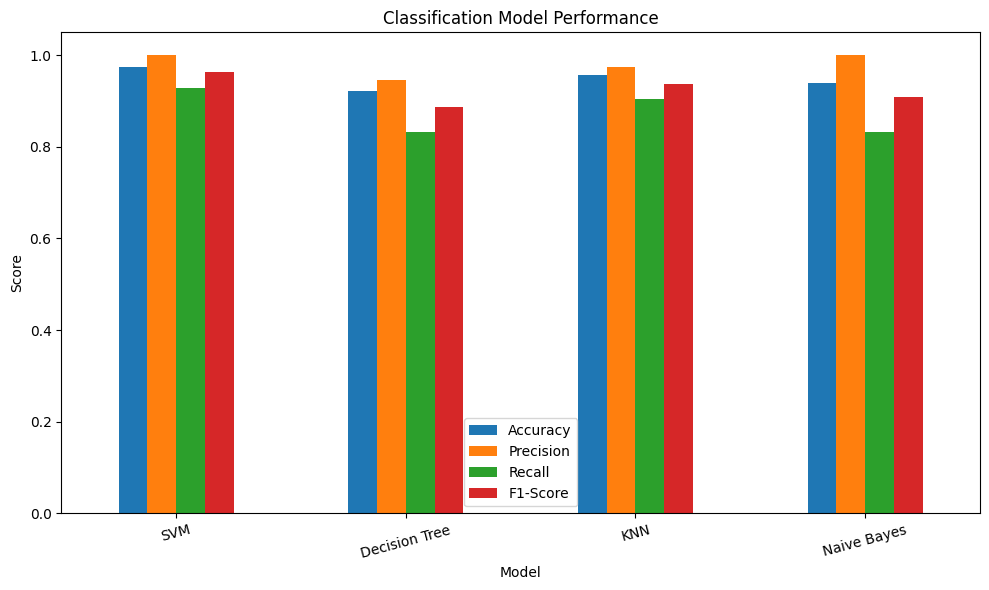

In [8]:
results_df[
    ["Accuracy", "Precision", "Recall", "F1-Score"]
].plot(kind="bar", figsize=(10, 6))

plt.title("Classification Model Performance")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

#**TC09: Generate confusion matrices**

In [9]:
from sklearn.metrics import confusion_matrix

for name, model in models.items():
    y_pred = model.predict(X_test)

    print(f"\n{name} Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))


SVM Confusion Matrix:
[[72  0]
 [ 3 39]]

Decision Tree Confusion Matrix:
[[70  2]
 [ 7 35]]

KNN Confusion Matrix:
[[71  1]
 [ 4 38]]

Naive Bayes Confusion Matrix:
[[72  0]
 [ 7 35]]


#**TC10: Identify the best model**

In [10]:
print("Best Models:")

for metric in ["Accuracy", "Precision", "Recall", "F1-Score"]:
    print(f"{metric}: {results_df[metric].idxmax()}")

print("Lowest Log Loss:", results_df["Log Loss"].idxmin())

Best Models:
Accuracy: SVM
Precision: SVM
Recall: SVM
F1-Score: SVM
Lowest Log Loss: SVM
